# 03 - Dose-Response Regression Results
Loads and displays the real regression results produced by `src/dose_response.py`. Run `python main.py` first.

**Scope reminder:** these models predict an in-vitro cell-line drug-sensitivity summary statistic (LN_IC50 / AUC), not a human patient's clinical dose. See `docs/LIMITATIONS.md`.

In [1]:
import pandas as pd
from IPython.display import Image, display

pooled = pd.read_csv('../results/regression_results.csv')
pooled[['experiment','model','MAE','RMSE','R2','pearson_r','spearman_r']].round(3)

,experiment,model,MAE,RMSE,R2,pearson_r,spearman_r
0,pooled_LN_IC50,LinearRegression,2.446,2.970,-0.263,0.349,0.271
1,pooled_LN_IC50,RandomForest,1.283,1.636,0.617,0.792,0.659
2,pooled_LN_IC50,XGBoost,1.305,1.650,0.610,0.785,0.647
3,pooled_AUC,LinearRegression,0.082,0.113,0.062,0.307,0.289
4,pooled_AUC,RandomForest,0.061,0.088,0.436,0.668,0.585
5,pooled_AUC,XGBoost,0.063,0.089,0.427,0.657,0.560


## Pooled model: predicted vs actual (held-out cell lines)

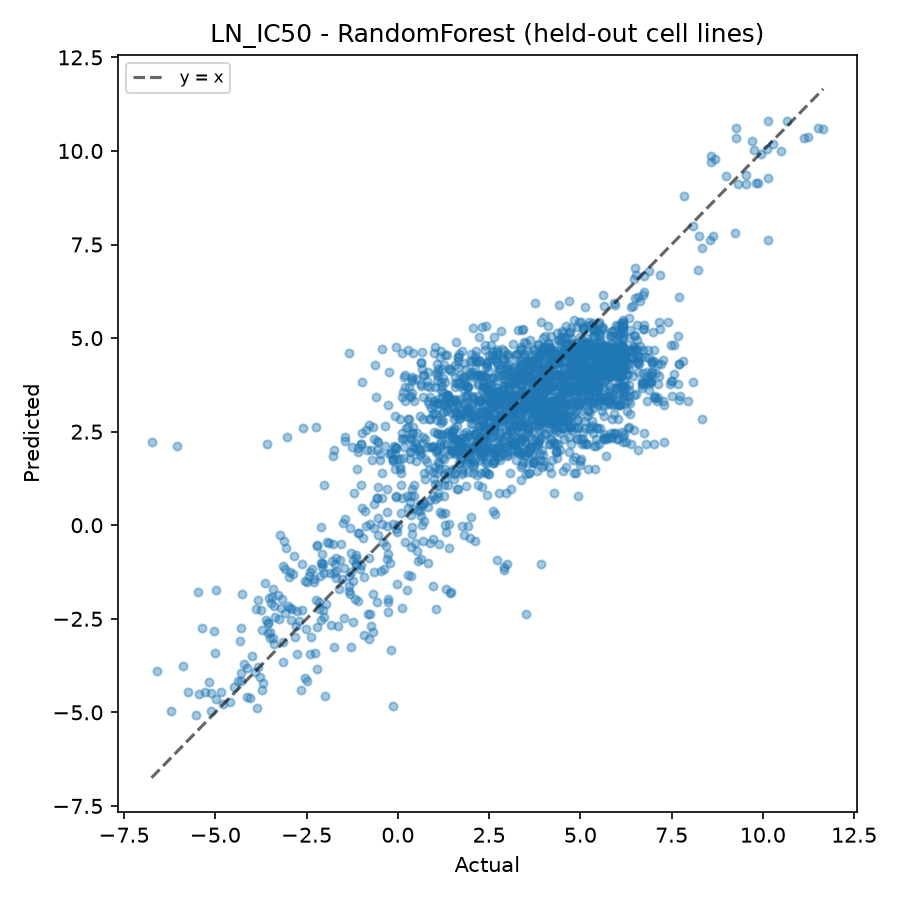

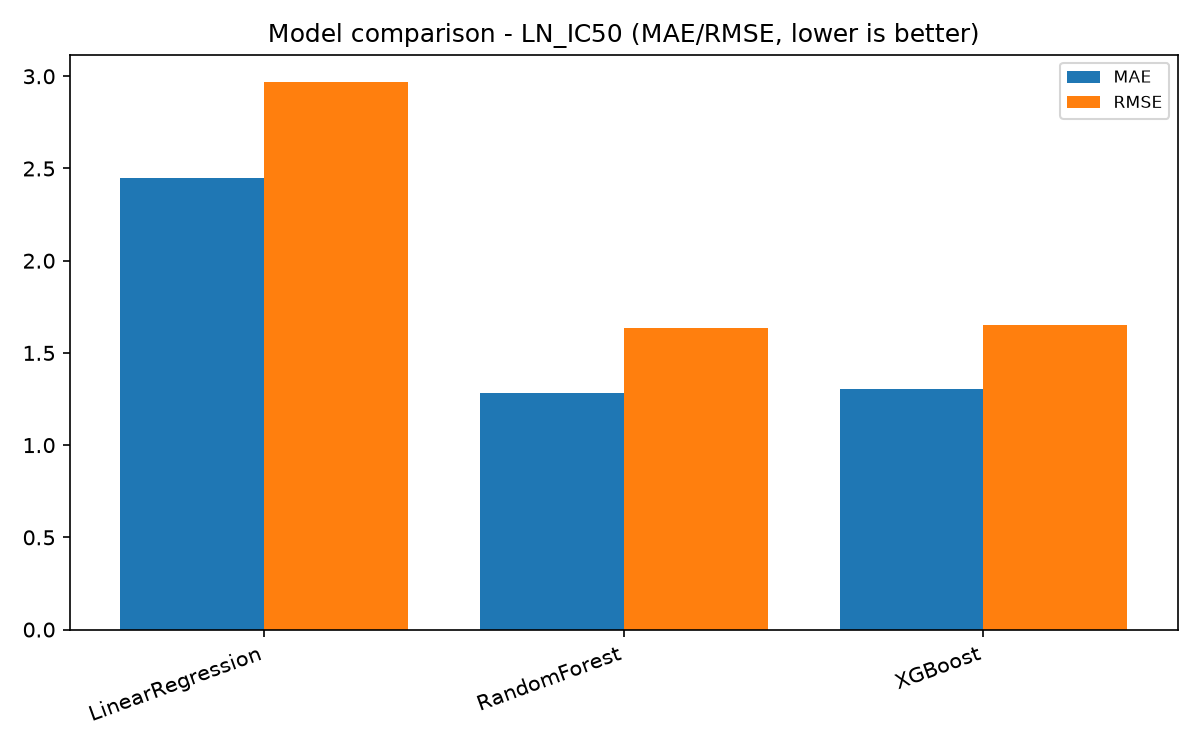

In [2]:
display(Image('../figures/predicted_vs_actual_LN_IC50_RandomForest.png'))
display(Image('../figures/model_comparison_dose_response.png'))

## Representative CRC drugs (ferroptosis genes only, leave-one-out CV)

In [3]:
drugs = pd.read_csv('../results/representative_drug_results.csv')
drugs[['drug','model','n','MAE','RMSE','R2','pearson_r']].round(3)

,drug,model,n,MAE,RMSE,R2,pearson_r
0,5-Fluorouracil,LinearRegression,44,1.919,2.496,-1.231,0.309
1,5-Fluorouracil,RandomForest,44,1.161,1.468,0.228,0.483
2,Oxaliplatin,LinearRegression,44,2.136,2.848,-2.308,0.171
3,Oxaliplatin,RandomForest,44,1.123,1.392,0.210,0.459
4,Irinotecan,LinearRegression,44,2.534,3.815,-4.606,-0.067
5,Irinotecan,RandomForest,44,1.043,1.327,0.322,0.568
6,Sorafenib,LinearRegression,42,1.785,2.136,-2.626,0.223
7,Sorafenib,RandomForest,42,0.777,0.987,0.226,0.482


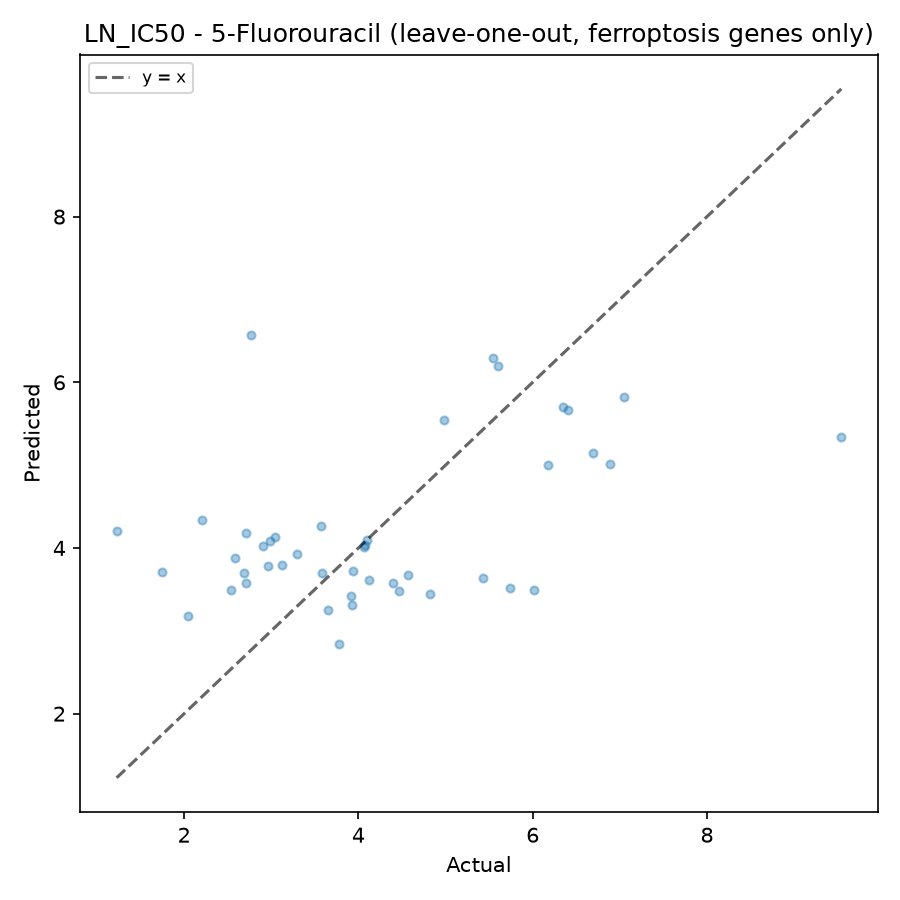

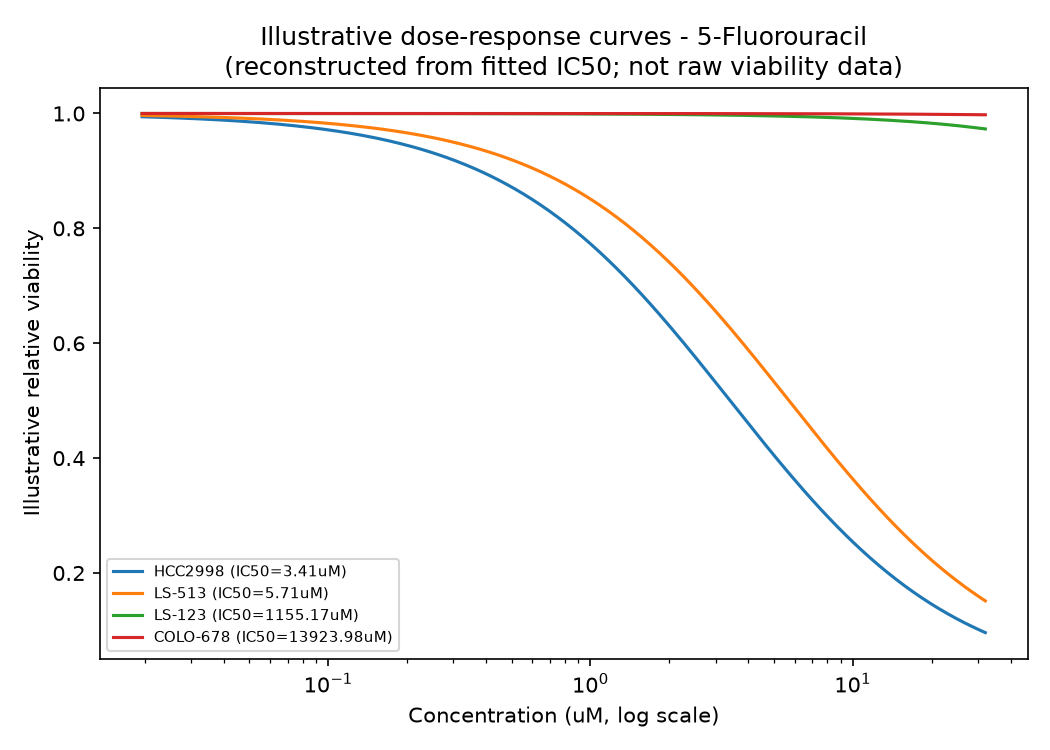

In [4]:
display(Image('../figures/predicted_vs_actual_5-Fluorouracil_LOOCV.png'))
display(Image('../figures/dose_response_curve_5-Fluorouracil.png'))

## Interpretability: top ferroptosis genes for LN_IC50 prediction

,gene,perm_importance_mean,perm_importance_std
0,HOXC11,0.002058,0.000427
1,HAMP,0.001633,0.000600
2,CARS1,0.001439,0.000352
3,AIFM2,0.001252,0.000316
4,FDFT1,0.000510,0.000103
5,SLC7A11,0.000483,0.000137
6,NOX4,0.000422,0.000136
7,CDKN2A,0.000381,0.000053
8,GDF15,0.000310,0.000079
9,ABCC1,0.000287,0.000075


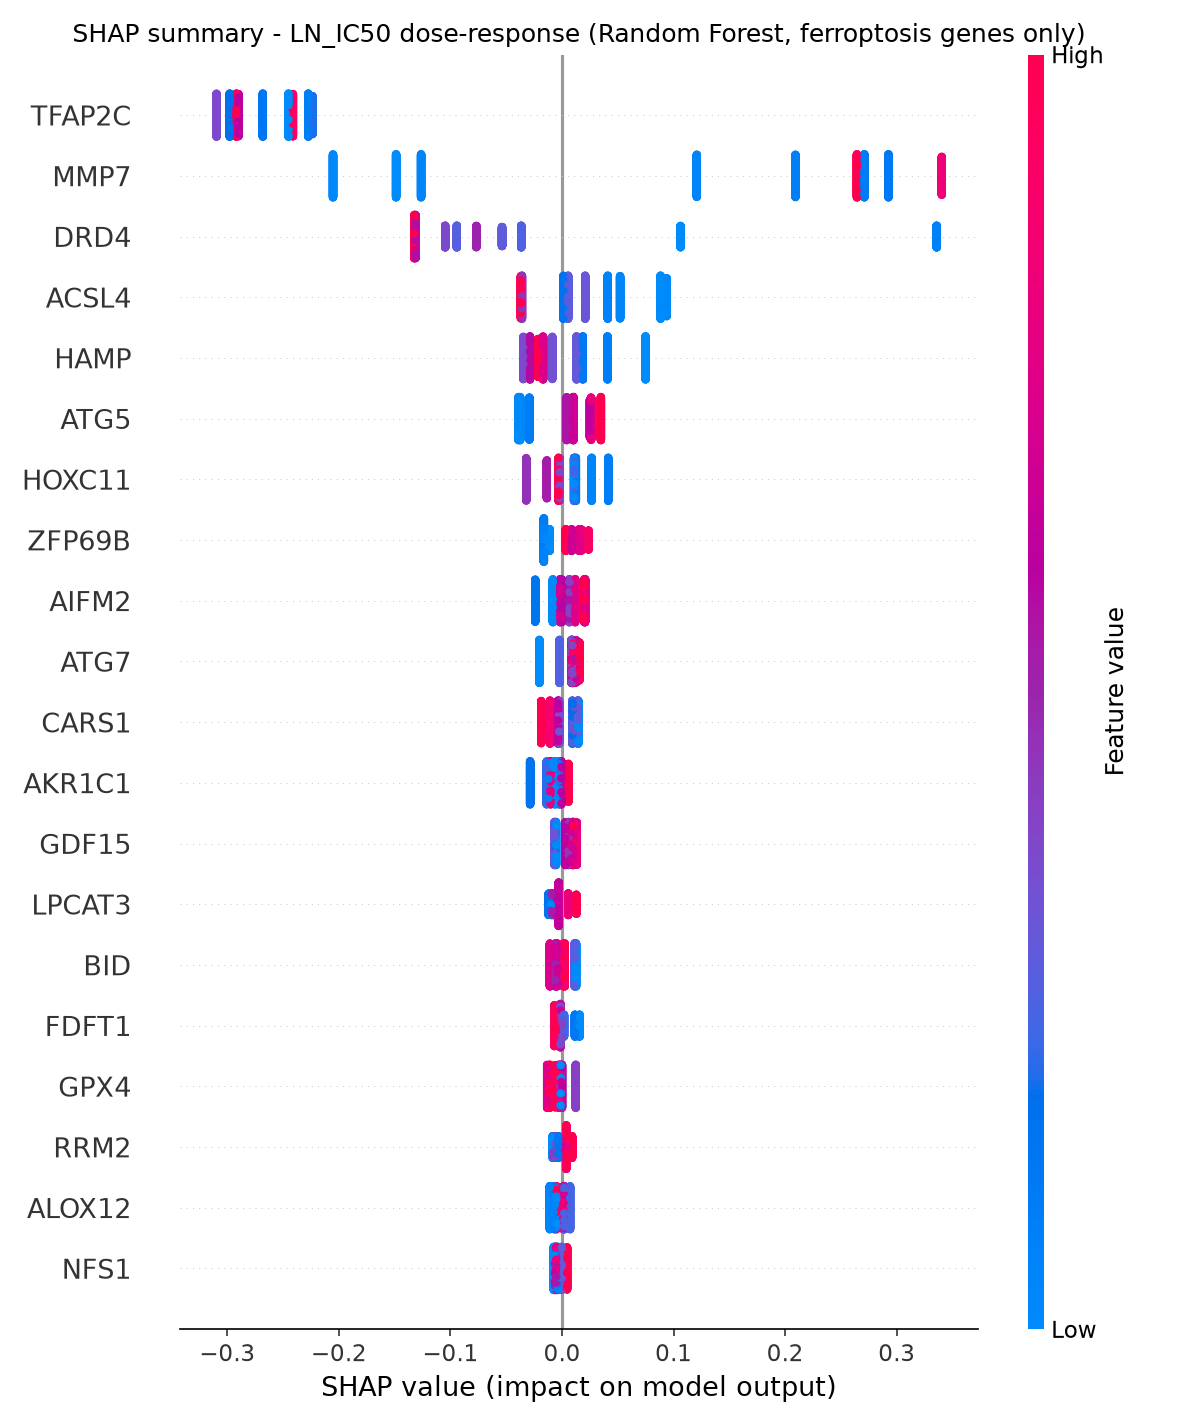

In [5]:
perm = pd.read_csv('../results/feature_importance_regression_permutation.csv')
display(perm.head(10))
display(Image('../figures/shap_summary_dose_response.png'))